<a href="https://colab.research.google.com/github/05haileywang/ECON3916_PS1/blob/main/ECON3916_PS1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [551]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.



*Your answer here.*

Two adult household with two incomes and one child. They own their home in a suburban area. They both own cars that they use to commute to their full time jobs. They spend their money on their mortgage, groceries, gas, recreaction, and childcare.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [552]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Mortgage","Price_2019": 1200, "Price_2024": 1550, "weight": 0.5},
    {"Item": "Groceries","Price_2019": 650,  "Price_2024": 850,  "weight": 0.12},
    {"Item": "Gas","Price_2019": 150,  "Price_2024": 190,  "weight": 0.09},
    {"Item": "Child care","Price_2019": 900,  "Price_2024": 1200, "weight": 0.1},
    {"Item": "Recreation","Price_2019": 400,  "Price_2024": 520,  "weight": 0.1},
    {"Item": "Utilities","Price_2019": 200,  "Price_2024": 250,  "weight": 0.09}
]


In [553]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [554]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    return 100 * sum(
        item["weight"] * item[current_key] / item[base_key] for item in basket
    )

In [555]:
laspeyres(household_basket, "Price_2019", "Price_2024")

129.25897435897434

In [556]:
# 1. the unweighted average price change across categories
change = [(item["Price_2024"] - item["Price_2019"]) / item["Price_2019"] * 100 for item in household_basket]
unweighted = sum(change) / len(change)
# 2. your weighted Laspeyres index
weighted = laspeyres(household_basket, "Price_2019", "Price_2024") - 100
# 3. the gap between them
gap = weighted - unweighted
print(unweighted, weighted, gap)

29.155982905982906 29.258974358974342 0.10299145299143575


**Why do the two differ, and which would you defend to the client?**

*Your answer here.*
The unweighted average treats each category the same, giving each equal weight. The Laspeyres index weights the categories according to their share of total spending. The numbers differ because inflation varied across categories, as did the categories' weights. I would defend the Laspeyres index because it weights the categories according to the household's spending pattern. The unweighted average would oversimplify the process and would miscalculate the household's real cost increase.

---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [557]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "CUSR0000SEHC", "CUSR0000SETB01", "CUSR0000SEEB", "CPIRECSL", "CUSR0000SAH21"]

In [558]:
def load_fred(series_id, start="1947-01-01", end=None):
    url = (f"https://fred.stlouisfed.org/graph/fredgraph.csv?"
           f"id={series_id}&cosd={start}")
    if end is not None:
        url += f"&coed={end}"
    frame = pd.read_csv(url)
    frame.columns = ["date", series_id]
    frame["date"] = pd.to_datetime(frame["date"])
    frame[series_id] = pd.to_numeric(frame[series_id], errors="coerce")
    return frame.set_index("date")[series_id].dropna()

series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "CUSR0000SEHC", "CUSR0000SETB01", "CUSR0000SEEB", "CPIRECSL", "CUSR0000SAH21"]
proxy = pd.DataFrame()

for id in series_ids:
    proxy[id] = load_fred(id, start="2019-01-01")

print(len(proxy), "monthly observations")
print("Date range:", proxy.index.min().date(), "to", proxy.index.max().date())
proxy.head()

91 monthly observations
Date range: 2019-01-01 to 2026-08-01


,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02,CUSR0000SEHC,CUSR0000SETB01,CUSR0000SEEB,CPIRECSL,CUSR0000SAH21
date,,,,,,,,,
2019-01-01,252.561,325.314,241.581,142.214,320.571,208.730,754.086,120.364,200.799
2019-02-01,253.319,326.220,242.111,142.272,321.560,217.237,755.996,120.119,200.169
2019-03-01,254.277,327.539,242.482,141.218,322.538,230.013,759.001,120.455,201.263
2019-04-01,255.233,328.816,241.219,139.895,323.616,245.651,760.272,120.644,201.013
2019-05-01,255.296,329.617,241.642,138.573,324.449,242.557,761.834,120.155,200.175


| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` |overall consumer prices and it is a good baseline estimate for the household's total cost change|it uses data from the national spending survey and the weights calculated from that survey. The weight of my household likely differs|
| `CUSR0000SEHA` |This series is based on the rent of the primary residence, which is similar and usable for mortgages|This measures rent of a household, not the mortgage.|
| `CUSR0000SAF11` |This measures grocery prices which is an exact match for one of my categories|It uses a national average, which does not capture the nuances of this household's diet|
| `CUSR0000SETA02` |This is a series for used car prices, but my household does not have this|It's not very helpful because my household does not have this expense |
| `CUSR0000SETB01` |This is a series for gas and it's a proxy in my household|This is a national average, so it misses some local nuances in price. It is also an average of all gas types.|
| `CUSR0000SEEB` |This is a series for childcare prices and it covers all types of childcare, which my basket includes|It is quite a broad category that encompases all types of childcare.|
| `CUSR0000SAH21` |This is a series for used household energy usage which is included in my basket.|This only includes electricity usage and it does not cover water utilies|
| `CPIRECSL` |This is a series for recereation which is a component of my basket. It is a direct match|It fails to account for income and spending power in my particular household|


### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [559]:
# Rebase to 2019 = 100
def rebase_series(data, base_year=2019):
    base = data.loc[data.index.year == base_year].mean()
    return data / base * 100

rebased = rebase_series(proxy, base_year=2019)

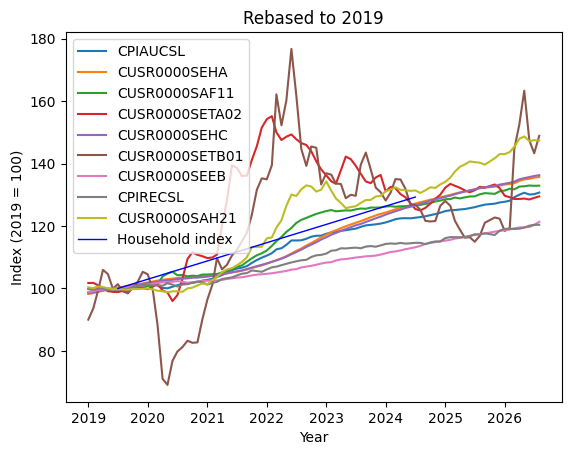

In [560]:
# One chart: every rebased series, plus your household index
household_2024 = laspeyres(household_basket, "Price_2019", "Price_2024")

for col in rebased.columns:
    plt.plot(rebased.index, rebased[col], label=col)

plt.plot(
    [pd.Timestamp("2019-07-01"), pd.Timestamp("2024-07-01")],
    [100, household_2024],
    label="Household index",
    color="blue",
    linewidth=1,
)

plt.xlabel("Year")
plt.ylabel("Index (2019 = 100)")
plt.title("Rebased to 2019")
plt.legend()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [561]:
# First observation, last observation, frequency and missing months, for every series
for col in proxy.columns:
    s = proxy[col].dropna()
    monthly = s.asfreq("MS")
    gaps = monthly[monthly.isna()]

    print(f"{col}: first {s.index.min().date()}, last {s.index.max().date()}, "
          f"monthly, {monthly.isna().sum()} missing months")

    for d in gaps.index:
        print("    missing:", d.date())

CPIAUCSL: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SEHA: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SAF11: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SETA02: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SEHC: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SETB01: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SEEB: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CPIRECSL: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01
CUSR0000SAH21: first 2019-01-01, last 2026-08-01, monthly, 1 missing months
    missing: 2025-10-01


| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
CPIAUCSL|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SEHA|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SAF11|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SETA02|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SEHC|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SETB01|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SEEB|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CPIRECSL|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)
CUSR0000SAH21|2019-01-01|2026-08-01|Monthly|1 (2025-10-01)

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [562]:
# Start dates side by side, and the common sample
common_sample = pd.DataFrame()
for sid in series_ids:
    common_sample[sid] = load_fred(sid, start="1947-01-01")

longest = 0
for col in common_sample.columns:
    s = common_sample[col].dropna()
    print(col, "starts", s.index.min().date())
    if len(s) > longest:
        longest = len(s)

common = common_sample.dropna()

print("Common sample starts:", common.index.min().date())
print("Common sample length:", len(common), "months")
print("Months of the longest series discarded:", longest - len(common))

CPIAUCSL starts 1947-01-01
CUSR0000SEHA starts 1981-01-01
CUSR0000SAF11 starts 1952-01-01
CUSR0000SETA02 starts 1953-01-01
CUSR0000SEHC starts 1983-01-01
CUSR0000SETB01 starts 1967-01-01
CUSR0000SEEB starts 1978-01-01
CPIRECSL starts 1993-01-01
CUSR0000SAH21 starts 1967-01-01
Common sample starts: 1993-01-01
Common sample length: 403 months
Months of the longest series discarded: 552


In [563]:
# Headline comparison: full history vs common sample
common = common_sample.dropna()

print("Full history vs common sample")
for col in common_sample.columns:
    s = common_sample[col].dropna()
    print(f"  {col}: {(s.iloc[-1] / s.iloc[0] - 1) * 100:.1f}%")

print("Common sample only:")
for col in common.columns:
    s = common[col]
    print(f"  {col}: {(s.iloc[-1] / s.iloc[0] - 1) * 100:.1f}%")

Full history vs common sample
  CPIAUCSL: 1455.5%
  CUSR0000SEHA: 430.5%
  CUSR0000SAF11: 929.9%
  CUSR0000SETA02: 530.5%
  CUSR0000SEHC: 341.1%
  CUSR0000SETB01: 1212.4%
  CUSR0000SEEB: 1509.6%
  CPIRECSL: 61.9%
  CUSR0000SAH21: 1283.9%
Common sample only:
  CPIAUCSL: 134.0%
  CUSR0000SEHA: 201.8%
  CUSR0000SAF11: 132.7%
  CUSR0000SETA02: 42.0%
  CUSR0000SEHC: 179.9%
  CUSR0000SETB01: 240.1%
  CUSR0000SEEB: 324.0%
  CPIRECSL: 61.9%
  CUSR0000SAH21: 168.5%


**What restricting to the common sample assumes, and what not restricting assumes:**

*Your answer here.*

1. The common sample assumes that the period in which all of the samples exist is a representative sample. However, older data that is outside of the common sample period is discarded. This must be documented to ensure that the reader understands that there was data outside of the common sample.

2. The not restricted common sample assumes that the timeline is the same for both series. However, this is not the case. Samples that have a longer total period than the common sample have a larger total change that is not represented in the final data.



### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

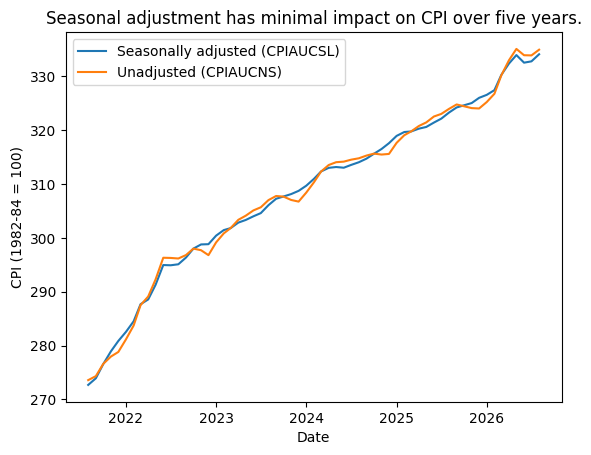

In [564]:
# Seasonally adjusted vs unadjusted, last five years
seasonally_adjusted = load_fred("CPIAUCSL", start="2021-08-01")
not_seasonally_adjusted = load_fred("CPIAUCNS", start="2021-08-01")

plt.plot(seasonally_adjusted.index, seasonally_adjusted, label="Seasonally adjusted (CPIAUCSL)")
plt.plot(not_seasonally_adjusted.index, not_seasonally_adjusted, label="Unadjusted (CPIAUCNS)")
plt.xlabel("Date")
plt.ylabel("CPI (1982-84 = 100)")
plt.title("Seasonal adjustment has minimal impact on CPI over five years.")
plt.legend()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

*Your answer here.*

The gap between the two lines represent the different from making the seasonal adjustment. The seasonally adjusted series belongs in this brief because it shows the price trends in CPI without the seasonal component that could be mistaken for real price changes.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

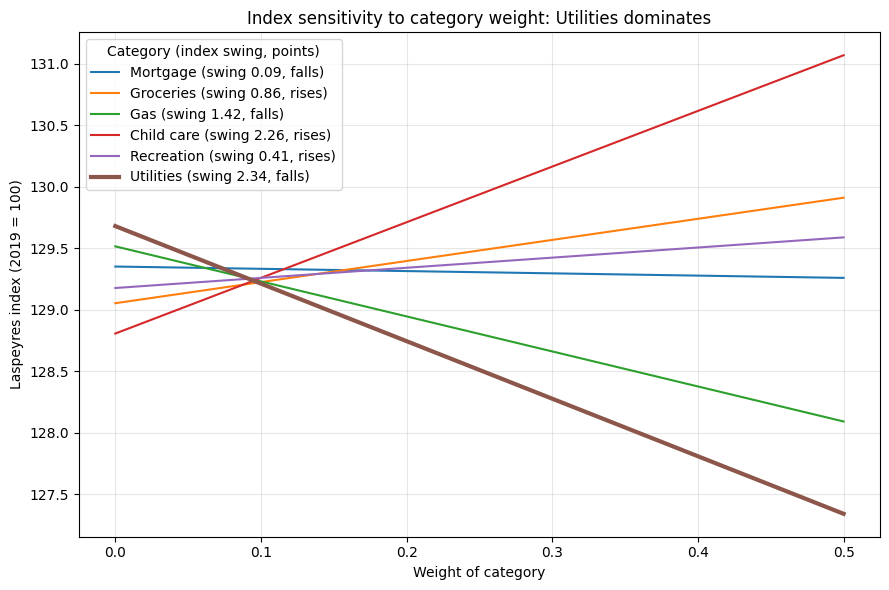

            swing direction
Utilities    2.34     falls
Child care   2.26     rises
Gas          1.42     falls
Groceries    0.86     rises
Recreation   0.41     rises
Mortgage     0.09     falls


In [565]:
# Paste the AI's code here, run it, and correct it where it is wrong

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# household_basket: list of dicts with Item, Price_2019, Price_2024, weight
df = pd.DataFrame(household_basket)
df["relative"] = df["Price_2024"] / df["Price_2019"]
base_weights = df["weight"] / df["weight"].sum()   # make sure base weights sum to 1

weight_grid = np.linspace(0, 0.5, 101)

def laspeyres_index(weights, relatives):
    # Laspeyres index = base-weighted average of price relatives, scaled to 100
    return 100 * np.sum(weights * relatives)

sweep = {}
for i in df.index:
    # Why renormalise: weights must sum to 1 for the index to remain a true
    # weighted average. If we change one weight and leave the rest alone, the
    # weights sum to something other than 1 and the index drifts for reasons
    # unrelated to prices. Scaling the others in proportion keeps their relative
    # mix intact, so the only thing changing is the category under test.
    others_share = base_weights.drop(i) / base_weights.drop(i).sum()

    results = []
    for w in weight_grid:
        weights = others_share * (1 - w)
        weights.loc[i] = w
        results.append(laspeyres_index(weights.sort_index(), df["relative"]))
    sweep[df.loc[i, "Item"]] = np.array(results)

# Sensitivity = total change in the index across the 0 to 0.5 sweep
swing = pd.Series({item: v.max() - v.min() for item, v in sweep.items()})
swing = swing.sort_values(ascending=False)
most_sensitive = swing.index[0]

# CHANGE: direction comes from the data (index at w = 0.5 vs w = 0)
direction = pd.Series({item: "rises" if v[-1] > v[0] else "falls" for item, v in sweep.items()})

fig, ax = plt.subplots(figsize=(9, 6))
for item, values in sweep.items():
    is_top = item == most_sensitive
    ax.plot(
        weight_grid,
        values,
        linewidth=3 if is_top else 1.5,
        label=f"{item} (swing {swing[item]:.2f}, {direction[item]})",
    )

ax.set_xlabel("Weight of category")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weight: {most_sensitive} dominates")
ax.legend(title="Category (index swing, points)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(pd.DataFrame({"swing": swing.round(2), "direction": direction[swing.index]}))

**What did the model get wrong, or get right in a way you had to check? Show the check.**

*Your answer here.*

The model writeup labels the mortgage at flat, but in reality, it declines slightly from 129.35 to 129.26.

### AI Transcript

**Model:** Sonnet 5.5; **Date:** 10/9/2026

*Paste the prompt exactly as you sent it, then the model's reply exactly as it
came back, before your corrections.*

[Prep] Act as an applied economist who builds reproducible analysis for client deliverables.
[Request] I have a household price index built as a weighted Laspeyres over six spending categories, in a list of dicts named household_basket with keys Item, Price_2019, Price_2024 and weight. Write Python that sweeps each category’s weight from 0 to 0.5, holding the others in proportion, recomputes the index, and produces a single chart showing which category’s weight the result is most sensitive to.
[Iterate] numpy, pandas and matplotlib only. Reuse my variable names. No deprecated matplotlib arguments.
[Mechanism Check] Add comments explaining why renormalising the other weights is necessary, and what it would mean if the index were highly sensitive to a single category.
[Evaluate] Tell me which category dominates my result and what I should say to a client about it.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# household_basket: list of dicts with Item, Price_2019, Price_2024, weight
df = pd.DataFrame(household_basket)
df["relative"] = df["Price_2024"] / df["Price_2019"]
base_weights = df["weight"] / df["weight"].sum()   # make sure base weights sum to 1

weight_grid = np.linspace(0, 0.5, 101)

def laspeyres_index(weights, relatives):
    # Laspeyres index = base-weighted average of price relatives, scaled to 100
    return 100 * np.sum(weights * relatives)

sweep = {}
for i in df.index:
    # Why renormalise: weights must sum to 1 for the index to remain a true
    # weighted average. If we change one weight and leave the rest alone, the
    # weights sum to something other than 1 and the index drifts for reasons
    # unrelated to prices. Scaling the others in proportion keeps their relative
    # mix intact, so the only thing changing is the category under test.
    others_share = base_weights.drop(i) / base_weights.drop(i).sum()

    results = []
    for w in weight_grid:
        weights = others_share * (1 - w)
        weights.loc[i] = w
        results.append(laspeyres_index(weights.sort_index(), df["relative"]))
    sweep[df.loc[i, "Item"]] = np.array(results)

# Sensitivity = total change in the index across the 0 to 0.5 sweep
swing = pd.Series({item: v.max() - v.min() for item, v in sweep.items()})
swing = swing.sort_values(ascending=False)
most_sensitive = swing.index[0]

fig, ax = plt.subplots(figsize=(9, 6))
for item, values in sweep.items():
    is_top = item == most_sensitive
    ax.plot(
        weight_grid,
        values,
        linewidth=3 if is_top else 1.5,
        label=f"{item} (swing {swing[item]:.2f})",
    )

ax.set_xlabel("Weight of category (others rescaled proportionally)")
ax.set_ylabel("Laspeyres index (2019 = 100)")
ax.set_title(f"Index sensitivity to category weight: {most_sensitive} dominates")
ax.legend(title="Category (index swing, points)")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

print(swing.round(2))

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

Hello Director,

Based on the findings in this lab, I can conclude that the consumer basket that I created experienced a price increase of 29.3 percent from 2019 to 2024. I have high confidence in the mathematical outcomes from the model. Reweighting the model using the Laspeyres index did not actually change the index. This demonstrate that the prices changes are close together and are not easily swayed from reweighting based on the categories according to their share of total spending. Utilities and childcare were the most sensitive to changes, as they swung 2.34 and 2.26 index points respectively. Mortgage was correlated with half of the total spend for this household, yet the index only changed 0.09 points. This demonstrate that its inflation is similar to the rest of the basket. Moving any individual category's weight from 0 to 50 percent did not change the index greatly. It remained between 127.3 and 131.1.

To better understand the findings in the index and the inflation, I would recommend that you re verify the share of total spending that utilities and child care has in this basket. This is because they are the most sensitive categories and can change the basket greatly if they are inaccurate.

*Your finding here.*

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub